# 04 — Filtrage collaboratif (SVD)


In [1]:
import sys, os
sys.path.append("..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.data_loader import load, split_per_user, save_processed
DATA = "../data/raw/interactions_real_rich_processed.csv"
df = load(DATA)
train, test = split_per_user(df)

Text(0.5, 0, 'k')

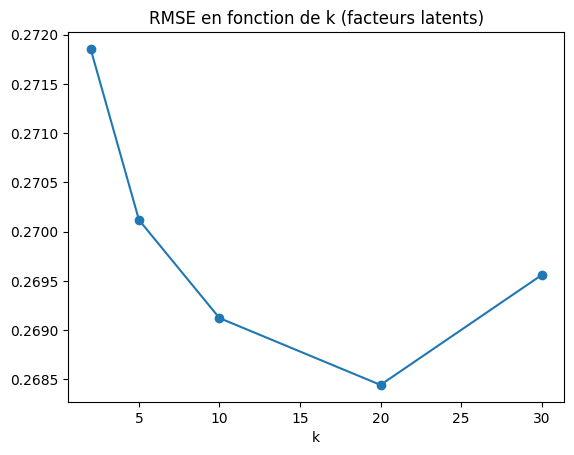

In [2]:
from src.student_model import StudentModel
from src.collaborative import SVDRecommender
from src.evaluation import rmse_mae
sm = StudentModel().fit(train)
res = {}
for k in [2, 5, 10, 20, 30]:
    cf = SVDRecommender(sm, k=k).fit(train); res[k] = rmse_mae(cf.score, test, sm)[0]
pd.Series(res).plot(marker='o', title='RMSE en fonction de k (facteurs latents)'); plt.xlabel('k')